# Name : M.Abuzar Shoukat
# Reg. No. = 04102313064

In [69]:
import re, json, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy, torch
from PIL import Image, ImageDraw, ImageFont
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score)

nlp = spacy.load('en_core_web_sm')
print('spaCy', spacy.__version__)

spaCy 3.8.16


In [70]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()
X = vec.fit_transform(docs)
print(pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3']).round(3))

# d1 haath se: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

print('idf free =', round(idf['free'], 3), '| idf now =', round(idf['now'], 3))
print('cosine d2,d3 =', round(float(X[1].multiply(X[2]).sum()), 3))

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}
idf free = 1.288 | idf now = 1.0
cosine d2,d3 = 0.544


## Write it (Part 1)

- **IDF of "free":** it appears in 2 of the 3 documents, so idf = ln((1 + 3) / (1 + 2)) + 1 = ln(4/3) + 1 = 0.288 + 1 = **1.288**.
- **IDF of "now":** it appears in all 3 documents, so idf = ln((1 + 3) / (1 + 3)) + 1 = ln(1) + 1 = **1.000**.
- **Why "now" has the lowest weight:** a word that appears in every document cannot help tell the documents apart, so its idf is the smallest possible value (1.0). After L2 normalisation this gives "now" the smallest weight in d1 (0.345), compared with 0.584 for the rarer words "win" and "cash".
- **Cosine similarity of d2 and d3:** the only words they share are "call" and "now": 0.548 × 0.620 + 0.425 × 0.481 = 0.340 + 0.204 = **0.544**. This matches the 0.54 on slide 10, and my hand-computed d1 values were identical to scikit-learn's output.

In [71]:
path = '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv'
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



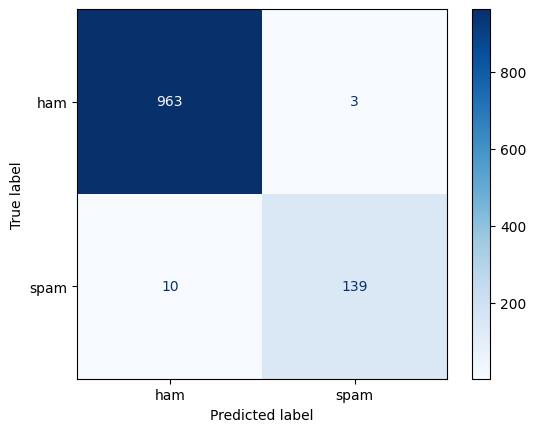

In [72]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42, stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

In [73]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
top_spam = list(terms[order[-12:]][::-1])
top_ham = list(terms[order[:12]])
print('Most spam-like :', top_spam)
print('Most ham-like  :', top_ham)

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


In [74]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}  '
          f'spam P {precision_score(y_te, p):.3f}  spam R {recall_score(y_te, p):.3f}  '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

word_f1 = f1_score(y_te, word_clf.predict(X_te), average='macro')
char_f1 = f1_score(y_te, char_clf.predict(X_te), average='macro')

# 3rd message apna likhein (Roman Urdu ya disguised spam)
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now',
          'kal milte hain, 5 baje',
          'Jeeto 50000 abhi, is link par click karo aur inam hasil karo']
for nm, clf in [('word', word_clf), ('char', char_clf)]:
    print(nm, dict(zip(tricky, clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974  spam P 0.979  spam R 0.933  features 12,128
char 2-5 grams  macro-F1 0.982  spam P 0.986  spam R 0.953  features 36,449
word {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.99), 'kal milte hain, 5 baje': np.float64(0.19), 'Jeeto 50000 abhi, is link par click karo aur inam hasil karo': np.float64(0.32)}
char {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12), 'Jeeto 50000 abhi, is link par click karo aur inam hasil karo': np.float64(0.39)}


In [75]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(len(err), 'misclassified')
print(err.sort_values('p_spam').to_string())

13 misclassified
                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no

In [76]:
my_tricky = ['Aap ka 5 lakh ka inam nikla hai, claim karne ke liye 0300 par call karein',
             'Fr33 m1nutes! Rep1y YES to cl@im ur b0nus now']
for nm, clf in [('word', word_clf), ('char', char_clf)]:
    print(nm, dict(zip(my_tricky, clf.predict_proba(my_tricky)[:, 1].round(2))))

word {'Aap ka 5 lakh ka inam nikla hai, claim karne ke liye 0300 par call karein': np.float64(0.72), 'Fr33 m1nutes! Rep1y YES to cl@im ur b0nus now': np.float64(0.59)}
char {'Aap ka 5 lakh ka inam nikla hai, claim karne ke liye 0300 par call karein': np.float64(0.47), 'Fr33 m1nutes! Rep1y YES to cl@im ur b0nus now': np.float64(0.52)}


## Write it (Part 2)

| Model | macro-F1 | spam precision | spam recall | features |
|---|---|---|---|---|
| word 1-2 grams | 0.974 | 0.979 | 0.933 | 12,128 |
| char 2-5 grams | 0.982 | 0.986 | 0.953 | 36,449 |

**Baseline:** spam is only 13.4% of the data (747 of 5,572 messages), so an "always ham" model already scores 86.6% accuracy. That is why macro-F1 and spam recall are the right measures here, not accuracy.

**Top features:** The spam-like features (call, txt, free, text, reply, claim, stop, mobile, www) are sensible, because they match real spam wording. However, "to", "your" and "uk" look like shortcuts: they are common words that happen to appear often in spam in this UK-based dataset. On the ham side, "my", "me", "ok", "can" and "what" are sensible conversational words, but "gt" and "lt" are most likely leftovers of HTML-escaped placeholders in the data, so they are dataset artefacts and not real evidence about ham.

**Error analysis (word model, 13 errors: 10 missed spam and 3 false alarms).** These are my own judgements:

| Message (shortened) | True | p(spam) | Verdict |
|---|---|---|---|
| "old ladies with tattoos" | spam | 0.09 | label error (reads like a harmless joke) |
| "scammers getting smart... vodafone no" | spam | 0.14 | genuinely ambiguous (a scam warning that is itself a scam) |
| "ringtoneking 84484" | spam | 0.19 | model error (too short, unseen word) |
| "arsenal dartboard for sale" | spam | 0.21 | genuinely ambiguous (private advert or commercial spam) |
| "ROMCAPspam... real breath of sunshine" | spam | 0.25 | model error (subscription spam wording not learned) |
| "Sorry I missed your call... I'm on 07090201529" | spam | 0.28 | genuinely ambiguous (looks personal; only the number gives it away) |
| "Police station toilet stolen" | spam | 0.31 | genuinely ambiguous (joke-subscription text) |
| "FreeMsg Hey there darling..." | spam | 0.41 | model error (clear cues, just under 0.5) |
| "Download as many ringtones as u like..." | spam | 0.42 | model error |
| "Can U get 2 phone NOW... Call me NOW on 09096102316" | spam | 0.46 | model error |
| "We have sent JD for Customer Service..." | ham | 0.62 | genuinely ambiguous (job or promotional style) |
| "Ok... Ur typical reply..." | ham | 0.64 | model error |
| "Waiting for your call." | ham | 0.85 | model error (shortcut: "call" and "your" are top spam features) |

In total there are 7 model errors, 1 label error and 5 ambiguous cases. Three spam messages scored between 0.41 and 0.46, so they are near-misses at the 0.5 threshold.

**Tricky messages (probability of spam):**

| Message | Type | Word | Char |
|---|---|---|---|
| "W1N a FR33 pr1ze!! txt CLAIM now" | disguised spam (lab) | 0.99 | 0.85 |
| "kal milte hain, 5 baje" | Roman Urdu ham (lab) | 0.19 | 0.12 |
| "Jeeto 50000 abhi, is link par click karo aur inam hasil karo" | my Roman Urdu spam | 0.32 | 0.39 |
| "Aap ka 5 lakh ka inam nikla hai, claim karne ke liye 0300 par call karein" | my Roman Urdu spam | 0.72 | 0.47 |
| "Fr33 m1nutes! Rep1y YES to cl@im ur b0nus now" | my disguised spam | 0.59 | 0.52 |

At a threshold of 0.5, the word model caught 3 of the 4 spam-type messages in the table (it missed "Jeeto..."), and the char model caught only 2 (it missed both Roman Urdu messages, one of them narrowly at 0.47). Both models correctly kept the Roman Urdu ham message below 0.5.

**Conclusion:** Character n-grams are slightly better on the test set overall (macro-F1 0.982 vs 0.974, spam recall 0.953 vs 0.933), but they use about three times as many features (36,449 vs 12,128). On my tricky messages they were not more robust: the word model scored higher on 3 of the 4 spam-type messages, because intact English cue words such as "txt", "CLAIM", "claim" and "call" still carried the signal even when other words were disguised. The Roman Urdu spam was only caught when it contained such English cues; "Jeeto ... inam hasil karo", with no English spam words, was missed by both. This is only 4 messages, so it is a small sample, but it shows that both models were trained on English text only and that a real fix needs Roman Urdu training examples.

In [77]:
nlp = spacy.load('en_core_web_sm')

sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    print([(e.text, e.label_) for e in nlp(s).ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


In [78]:
gold = [
    {('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'), ('30/09/2026', 'DATE')},
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'), ('Bilal Ahmed', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores_gen(nlp_model, sents, golds):
    tp = fp = fn = 0
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f1, 3)}

ner_scores = lambda m: ner_scores_gen(m, sentences, gold)
ner_before = ner_scores(nlp)
print('spaCy out of the box:', ner_before)   # expected F1 0.533

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


In [79]:
nlp = spacy.load('en_core_web_sm')   # dobara load, taake ruler do bar add na ho
ruler = nlp.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE', 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
ner_after = ner_scores(nlp)
print('spaCy + entity ruler:', ner_after)    # expected F1 0.875
for s in sentences:
    print([(e.text, e.label_) for e in nlp(s).ents])

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}
[('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'), ('30/09/2026', 'DATE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('Jazz', 'ORG'), ('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


In [80]:
dom_sents = [
    'Dr. Sana Malik at Shifa International reviewed the MRI on 14/10/2026.',
    'The MRI fee was Rs. 18,000 for patient Usman Tariq.',
    'Patient Hira Noor was referred to PIMS Islamabad on Friday.',
    'Radiologist Dr. Kamran Ali at Aga Khan University Hospital reported a mass on 02/11/2026.',
    'The CT scan cost PKR 9,500 at Shaukat Khanum Lahore.',
    # held-out (inse rules nahi likhe)
    'Dr. Imran Qureshi at Shifa International booked a follow-up for Monday.',
    'Ali Raza paid Rs. 12,000 at PIMS Islamabad on 20/10/2026.',
    'Neurosurgeon Dr. Farah Siddiqui from Aga Khan University Hospital operated on Tuesday.',
    'The MRI of Bilal Hussain was reported at Shaukat Khanum Lahore for PKR 22,000.',
    'Sadia Bibi travelled from Multan to Islamabad for treatment on 05/11/2026.']

dom_gold = [
    {('Sana Malik', 'PERSON'), ('Shifa International', 'ORG'), ('14/10/2026', 'DATE')},
    {('Rs. 18,000', 'MONEY'), ('Usman Tariq', 'PERSON')},
    {('Hira Noor', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'), ('Friday', 'DATE')},
    {('Kamran Ali', 'PERSON'), ('Aga Khan University Hospital', 'ORG'), ('02/11/2026', 'DATE')},
    {('PKR 9,500', 'MONEY'), ('Shaukat Khanum', 'ORG'), ('Lahore', 'GPE')},
    # held-out gold
    {('Imran Qureshi', 'PERSON'), ('Shifa International', 'ORG'), ('Monday', 'DATE')},
    {('Ali Raza', 'PERSON'), ('Rs. 12,000', 'MONEY'), ('PIMS', 'ORG'),
     ('Islamabad', 'GPE'), ('20/10/2026', 'DATE')},
    {('Farah Siddiqui', 'PERSON'), ('Aga Khan University Hospital', 'ORG'), ('Tuesday', 'DATE')},
    {('Bilal Hussain', 'PERSON'), ('Shaukat Khanum', 'ORG'), ('Lahore', 'GPE'),
     ('PKR 22,000', 'MONEY')},
    {('Sadia Bibi', 'PERSON'), ('Multan', 'GPE'), ('Islamabad', 'GPE'), ('05/11/2026', 'DATE')}]

# Rules sirf sentences 1-5 dekh kar
DOM_PATTERNS = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'}, {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Shifa International'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Aga Khan University Hospital'},
    {'label': 'ORG', 'pattern': 'Shaukat Khanum'},
    {'label': 'DATE', 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
]

nlp_base = spacy.load('en_core_web_sm')
nlp_dom = spacy.load('en_core_web_sm')
nlp_dom.add_pipe('entity_ruler', before='ner').add_patterns(DOM_PATTERNS)

dom_before = ner_scores_gen(nlp_base, dom_sents[5:], dom_gold[5:])
dom_after = ner_scores_gen(nlp_dom, dom_sents[5:], dom_gold[5:])
print('HELD-OUT (6-10) before rules:', dom_before)
print('HELD-OUT (6-10) after rules :', dom_after)
print('Sentences 1-5 after rules (optimistic):',
      ner_scores_gen(nlp_dom, dom_sents[:5], dom_gold[:5]))

print('\nRemaining errors on held-out set:')
for s, g in zip(dom_sents[5:], dom_gold[5:]):
    pred = {(e.text, e.label_) for e in nlp_dom(s).ents}
    if pred != g:
        print('-', s, '\n   missed:', g - pred, '\n   wrong :', pred - g)

HELD-OUT (6-10) before rules: {'precision': 0.5, 'recall': 0.474, 'f1': 0.486}
HELD-OUT (6-10) after rules : {'precision': 0.833, 'recall': 0.789, 'f1': 0.811}
Sentences 1-5 after rules (optimistic): {'precision': 0.929, 'recall': 0.867, 'f1': 0.897}

Remaining errors on held-out set:
- Ali Raza paid Rs. 12,000 at PIMS Islamabad on 20/10/2026. 
   missed: {('Islamabad', 'GPE')} 
   wrong : set()
- Neurosurgeon Dr. Farah Siddiqui from Aga Khan University Hospital operated on Tuesday. 
   missed: set() 
   wrong : {('Neurosurgeon', 'PERSON')}
- The MRI of Bilal Hussain was reported at Shaukat Khanum Lahore for PKR 22,000. 
   missed: {('Bilal Hussain', 'PERSON'), ('Lahore', 'GPE')} 
   wrong : {('Hussain', 'PERSON')}
- Sadia Bibi travelled from Multan to Islamabad for treatment on 05/11/2026. 
   missed: {('Sadia Bibi', 'PERSON')} 
   wrong : {('Sadia Bibi', 'ORG')}


## Write it (Part 3)

| Set | Before rules (F1) | After rules (F1) |
|---|---|---|
| Provided 6 sentences (16 gold entities) | 0.533 (P 0.571, R 0.500) | 0.875 (P 0.875, R 0.875) |
| My held-out 5 sentences (19 gold entities) | 0.486 (P 0.500, R 0.474) | 0.811 (P 0.833, R 0.789) |

On my first 5 sentences, where the rules were written, the F1 after rules was 0.897. That number is optimistic, so the held-out 0.811 is the honest result.

**Errors out of the box:** "Engro Fertilizers" was labelled PERSON, "30/09/2026" was labelled GPE, and the mobile number "0300-1234567" was labelled DATE. "PIMS Islamabad" was merged into one LOC span instead of ORG + GPE, "Farmer Muhammad Aslam" included the title in the PERSON span, "PKR 45,000" was missed completely, "250,000" was tagged CARDINAL instead of the MONEY value "Rs. 250,000", and "Jazz" was missed.

**Why the rules helped:** the statistical model was trained mostly on general news text, so it does not know Pakistani organisations, PKR / Rs. formats or dd/mm/yyyy dates. The rules supply exactly that local knowledge.

**Errors that remain on my held-out set:**
- "Islamabad" was not tagged GPE after "PIMS" (the same happened in the provided set).
- "Neurosurgeon" was wrongly tagged PERSON.
- "Bilal Hussain" was cut to "Hussain", and "Lahore" was missed.
- "Sadia Bibi" was tagged ORG instead of PERSON.

On the provided set, 14 of the 16 gold entities were correct after the rules. The remaining errors were: "Islamabad" was not tagged GPE after "PIMS", "Farmer Muhammad Aslam" included the title "Farmer" in the span (so it did not match the gold "Muhammad Aslam" exactly), and "0300-1234567" was wrongly tagged DATE.

**How I would fix them:** I would use a mix of methods.
- Fixed formats and closed lists (phone numbers, dates, amounts, hospital and city names) are best handled by rules or by the regex from Part 4. For example, giving the mobile regex priority means a phone number can never become a DATE.
- Person names and span boundaries (titles like "Neurosurgeon", names tagged ORG) are an open-ended problem. Rules cannot list every Pakistani name, so I would train or fine-tune an NER model on a few hundred annotated hospital sentences.

**Honesty note:** the rules were written from sentences 1-5 only and scored on sentences 6-10, but the hospital names repeat across the two groups, so 0.811 is still somewhat optimistic. With hospitals the rules have never seen, the organisation rules would not fire.

In [81]:
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # mere domain patterns
    'scan_id': r'\bMRI-\d{6}\b',
    'age':     r'\baged?\s+(\d{1,3})\b',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

# (text, jo fields milni chahiye, jo NAHI milni chahiye)
tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', ['cnic', 'mobile'], []),
    ('Total Rs. 12,500.50 paid on 05/10/2026',        ['amount', 'date'], []),
    ('Invoice No. 4417 from info@engro.com.pk',       ['invoice', 'email'], []),
    ('Order 12345678901234 shipped',                  [], ['cnic']),
    ('Room 0300 on floor 3',                          [], ['mobile']),
    ('Patient aged 45, scan MRI-204518',              ['age', 'scan_id'], []),
    ('MRI-12 is not a valid ID',                      [], ['scan_id']),   # negative 1
    ('Scan 204518 without a prefix',                  [], ['scan_id']),   # negative 2
    ('Aged care ward is on floor 2',                  [], ['age']),       # negative 3
]
passed = 0
for text, must, mustnot in tests:
    got = extract_fields(text)
    ok = all(k in got for k in must) and all(k not in got for k in mustnot)
    passed += ok
    print('PASS' if ok else 'FAIL', got, '<-', text)
print(f'{passed}/{len(tests)} tests passed')

PASS {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']} <- CNIC 35202-1234567-1, mobile +92 300 1234567
PASS {'amount': ['12,500.50'], 'date': ['05/10/2026']} <- Total Rs. 12,500.50 paid on 05/10/2026
PASS {'email': ['info@engro.com.pk'], 'invoice': ['4417']} <- Invoice No. 4417 from info@engro.com.pk
PASS {} <- Order 12345678901234 shipped
PASS {} <- Room 0300 on floor 3
PASS {'scan_id': ['MRI-204518'], 'age': ['45']} <- Patient aged 45, scan MRI-204518
PASS {} <- MRI-12 is not a valid ID
PASS {} <- Scan 204518 without a prefix
PASS {} <- Aged care ward is on floor 2
9/9 tests passed


In [82]:
loose = {'scan_id': r'MRI-\d+', 'age': r'aged?\s+\d+'}
mid = r'\bMRI-\d{6}'
samples = ['scan MRI-204518', 'MRI-12 is not a valid ID', 'ref MRI-1234567',
           'see page 12 of the report', 'Patient aged 45']
for s in samples:
    print(f'{s:27s}| loose={re.findall(loose["scan_id"], s, re.I)} '
          f'no-end-boundary={re.findall(mid, s, re.I)} '
          f'final={re.findall(PATTERNS["scan_id"], s, re.I)} | '
          f'age loose={re.findall(loose["age"], s, re.I)} '
          f'age final={re.findall(PATTERNS["age"], s, re.I)}')

scan MRI-204518            | loose=['MRI-204518'] no-end-boundary=['MRI-204518'] final=['MRI-204518'] | age loose=[] age final=[]
MRI-12 is not a valid ID   | loose=['MRI-12'] no-end-boundary=[] final=[] | age loose=[] age final=[]
ref MRI-1234567            | loose=['MRI-1234567'] no-end-boundary=['MRI-123456'] final=[] | age loose=[] age final=[]
see page 12 of the report  | loose=[] no-end-boundary=[] final=[] | age loose=['age 12'] age final=[]
Patient aged 45            | loose=[] no-end-boundary=[] final=[] | age loose=['aged 45'] age final=['45']


## Write it (Part 4)

**Patterns (the lab patterns plus my two domain patterns):**
- `cnic`: `\b\d{5}-\d{7}-\d\b`
- `mobile`: `(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b`
- `amount`: `(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)`
- `date`: `\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b`
- `email`: `\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b`
- `invoice`: `\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b`
- `scan_id` (mine): `\bMRI-\d{6}\b`, a whole 6-digit MRI scan number.
- `age` (mine): `\baged?\s+(\d{1,3})\b`, "age" or "aged" followed by 1 to 3 digits.

**Test results:** 9 of 9 tests passed. The 4 positive tests extracted CNIC, mobile, amount, date, invoice, email, scan ID and age correctly. All 5 negative tests returned nothing, as required: "Order 12345678901234 shipped" (not a CNIC), "Room 0300 on floor 3" (not a mobile), "MRI-12 is not a valid ID", "Scan 204518 without a prefix" and "Aged care ward is on floor 2".

**A pattern that matched too much:** my first scan-ID pattern `MRI-\d+` also matched "MRI-12" (too short to be an ID) and "MRI-1234567" (7 digits). Adding an exact count and a start boundary (`\bMRI-\d{6}`) fixed "MRI-12", but it still matched the first six digits of "MRI-1234567" (it returned "MRI-123456"), so I added a closing `\b`. The final pattern `\bMRI-\d{6}\b` matches only a complete 6-digit ID. In the same way, my first age pattern `aged?\s+\d+` matched "age 12" inside "page 12", and the `\b` before "age" removed that false positive. The CNIC pattern uses the same ideas (exact counts and `\b`), which is why it ignores a 14-digit order number.

In [83]:
def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


In [84]:
import easyocr, matplotlib

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
font_path = '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf'
if not os.path.exists(font_path):
    font_path = os.path.join(matplotlib.get_data_path(), 'fonts/ttf/DejaVuSans.ttf')
font = ImageFont.truetype(font_path, 30)

lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
norm = lambda s: ' '.join(s.split())
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print(raw)
cer_raw, cer_clean = cer(truth, raw), cer(truth, clean)
print(f'CER raw {cer_raw:.3f}   after fixes {cer_clean:.3f}')

Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000


## Write it (Part 5)

**Task 5.1 (context rules):** the CER of the three OCR-damaged strings was 0.062 ("Invoice N0. 4417", 1 error in 16 characters), 0.059 ("PKR 12,5O0", 1 error in 17) and 0.143 ("3O/09/2O26", 2 errors in 14). After `fix_ocr`, all three dropped to **0.000**. The rules are safe because they only replace O/o with 0 and l/I with 1 when they sit next to digits, plus "N0." to "No.", so normal words are not changed.

**Task 5.2 (synthetic invoice):** CER raw = **0.000** and after correction = **0.000**. EasyOCR read all five lines of the invoice perfectly, so there was nothing left for the rules to repair.

**Why this is easier than a real phone photo:** the synthetic invoice is perfect OCR input: black text on a plain white background, one clean sans-serif font at a large size, straight horizontal lines, and no noise, blur, shadow, glare or perspective. A real phone photo of a paper invoice has uneven light, skew and perspective distortion, motion blur, compression, stamps, folds and small or faded print. On my own documents I therefore expect a clearly non-zero CER, with typical confusions such as O/0, l/1/I and S/5, and lost commas or dots inside amounts. The context rules would help with the letter-for-digit swaps, but they cannot repair characters that are missing or merged, and a rule like this could also wrongly change a valid code such as "O2".

In [85]:
def mask_pii(text):
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


In [86]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

print(glob.glob('/kaggle/input/*'))
W6_PATH = '/kaggle/input/datasets/abuzarbhatti068/week6-model/week6_model.pt'
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
print(ckpt.keys())
classes = ckpt['classes']
print(classes, ckpt['backbone'], ckpt['img_size'], ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf_img = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf_img(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

URGENT = ['headache', 'seizure', 'vomiting', 'blurred vision', 'weakness', 'numbness']

def text_evidence(note):
    doc = nlp(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

['/kaggle/input/datasets']
dict_keys(['state_dict', 'classes', 'backbone', 'img_size', 'grayscale'])
['glioma', 'meningioma', 'notumor', 'pituitary'] resnet18 224 True


In [87]:
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)                       # pehle mask
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

POSITIVE = 'glioma'              # classes mein se exact spelling
assert POSITIVE in classes, classes

cands = [f for f in glob.glob('/kaggle/input/**/*', recursive=True)
         if f.lower().endswith(('.jpg', '.jpeg', '.png'))
         and POSITIVE in f.lower() and 'test' in f.lower()]
print(len(cands), cands[:2])
EXAMPLE_IMAGE = cands[0]

note = ('Patient aged 45, severe headache for 2 weeks with vomiting and blurred '
        'vision. Seen at PIMS Islamabad on 12/09/2026. Mobile 0300-1234567.')
rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE)
out = json.dumps(rec, indent=2, ensure_ascii=False)
print(out)
print('Phone leaked in JSON?', '1234567' in out)     # False aana chahiye

400 ['/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_16.jpg', '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_87.jpg']
{
  "image": "Te-gl_16.jpg",
  "image_probabilities": {
    "glioma": 0.03,
    "meningioma": 0.97,
    "notumor": 0.0,
    "pituitary": 0.0
  },
  "note_masked": "Patient aged 45, severe headache for 2 weeks with vomiting and blurred vision. Seen at PIMS Islamabad on 12/09/2026. Mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "45",
        "DATE"
      ],
      [
        "2 weeks",
        "DATE"
      ],
      [
        "PIMS",
        "ORG"
      ],
      [
        "12/09/2026",
        "DATE"
      ]
    ],
    "fields": {
      "date": [
        "12/09/2026"
      ],
      "age": [
        "45"
      ]
    },
    "urgent_terms": [
      "headache",
      "vomiting",
      "blurred vision"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "note mentions: headache

In [88]:
import random
random.seed(0)
all_imgs = [f for f in glob.glob('/kaggle/input/**/*', recursive=True)
            if f.lower().endswith(('.jpg', '.jpeg', '.png')) and '/Testing/' in f]
res = {}
for cls in classes:
    files = [f for f in all_imgs if f'/Testing/{cls}/' in f]
    sample = random.sample(files, min(25, len(files)))
    hits = 0
    for f in sample:
        ev = image_evidence(f)
        hits += (max(classes, key=lambda c: ev[c]) == cls)
    res[cls] = f'{hits}/{len(sample)}'
print(res)

{'glioma': '20/25', 'meningioma': '23/25', 'notumor': '25/25', 'pituitary': '24/25'}


## Write it (Part 6)

**My JSON record** (image `Te-gl_16.jpg` from the Testing/glioma folder, positive class `glioma`):

```json
{
  "image": "Te-gl_16.jpg",
  "image_probabilities": {"glioma": 0.03, "meningioma": 0.97, "notumor": 0.0, "pituitary": 0.0},
  "note_masked": "Patient aged 45, severe headache for 2 weeks with vomiting and blurred vision. Seen at PIMS Islamabad on 12/09/2026. Mobile [PHONE].",
  "text_evidence": {
    "entities": [["45", "DATE"], ["2 weeks", "DATE"], ["PIMS", "ORG"], ["12/09/2026", "DATE"]],
    "fields": {"date": ["12/09/2026"], "age": ["45"]},
    "urgent_terms": ["headache", "vomiting", "blurred vision"]
  },
  "decision": "REFER",
  "reasons": ["note mentions: headache, vomiting, blurred vision"],
  "disclaimer": "Decision support only; a qualified human decides."
}
```

**Do the reasons make sense?** There is one reason: the note mentions headache, vomiting and blurred vision. These are genuine red-flag symptoms for a possible brain tumour, so REFER is a sensible decision. There is no image reason because P(glioma) = 0.03 is below the 0.5 threshold. This image comes from the glioma test folder, yet the model gave 0.97 to meningioma, so the image model made a mistake on this case. The system still reached a safe outcome only because the text evidence caught it.

**Is the image model broken, or was this one unlucky case?** To check, I ran the model on 25 random images per class from the Testing folder: glioma 20/25, meningioma 23/25, notumor 25/25 and pituitary 24/25, so 92 of 100 (92%) overall. This shows that the checkpoint loads and the preprocessing is correct, and that the glioma miss on Te-gl_16 is one of 5 glioma errors in that sample. Glioma is the weakest class (80%), and the 0.97 score for meningioma on this image suggests the two tumour types are being confused. One in five gliomas missed is too many to rely on the image model alone, which is another reason the text evidence and the human review step matter.

**One wrong entity in text_evidence:** "45" was labelled DATE, but it is the patient's age. This is harmless here, because the decision uses `urgent_terms` and the image probability and not the entity labels, and the age was captured correctly by the `age` regex field (45). It would be harmful if a downstream system stored entity labels, for example by treating 45 as a date. Also, "Islamabad" was not extracted at all after the PIMS rule fired, which does not change the decision but makes the record incomplete.

**Privacy check:** the note shows `Mobile [PHONE]`, and the search `'1234567' in out` printed `False`, so no phone digits appear anywhere in the JSON, including `entities` and `fields`. This is because `mask_pii` runs before `text_evidence`. The hospital name and visit date are not masked, which is fine for this lab but is a limitation.

**When the image and the note disagree:** this run shows one. The note is urgent, but the image model gives only 0.03 for glioma. The system must not let the image veto the note: it should output REFER, show both pieces of evidence, flag the disagreement, and let a qualified doctor decide. The opposite case (the image says glioma 0.80 but the note has no warning terms) should also give REFER, because a missed tumour costs far more than an extra review. This case also showed a design weakness: with four classes, using only "glioma" as the positive class would miss meningioma and pituitary tumours. A better score for "must not miss" is P(any tumour) = 1 − P(notumor), which would be about 1.0 for this image.

*This is a student project and decision support only, not a medical diagnosis.*

In [89]:
print('1. smooth idf =', round(np.log(1001 / 10) + 1, 3))
print('3. precision, recall, F1 =', 6/8, 6/10, round(2 * (6/8) * (6/10) / ((6/8) + (6/10)), 3))
print('4. CER =', round(cer('PKR 4,500', 'PKR 4,5OO'), 3))
print('5. fused =', 0.5 * 0.30 + 0.5 * 0.80)

1. smooth idf = 5.606
3. precision, recall, F1 = 0.75 0.6 0.667
4. CER = 0.222
5. fused = 0.55


## Check your understanding 
**1. Smooth IDF** (df = 9, N = 1000): idf = ln((1 + 1000) / (1 + 9)) + 1 = ln(100.1) + 1 = 4.606 + 1 = **5.606**

**2. Lowercasing and spam:** spam often uses CAPITAL LETTERS ("FREE", "WIN", "CLAIM NOW") as a signal. Lowercasing throws that signal away, so a shouting spam message looks the same as a normal one.

**3. NER metrics:** precision = 6 / 8 = **0.75**, recall = 6 / 10 = **0.60**, F1 = 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90 / 1.35 = **0.667**

**4. CER:** "PKR 4,500" has 9 characters; "PKR 4,5OO" has 2 substitutions (0 replaced by O, twice), so CER = 2 / 9 = **0.222**

**5. Fusion:** fused = w x image + (1 - w) x text = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **0.55**

**6. Mask before extraction:** if entity and field extraction run on the original note, the phone number or CNIC gets copied into `entities` and `fields`, so it leaks into logs and JSON even though the displayed note is masked. Masking first makes sure the sensitive value never enters any later step.